# **Projeto ADE | Mestrado Business Intelligence & Analytics**

## **Segmentação de Clientes e Sistema de Recomendação para um Retalhista**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025
---

### **Resumo**

Neste projeto, analisamos um conjunto de dados transacionais com o objetivo de segmentar clientes e desenvolver um sistema simples de recomendação de produtos. Começamos por uma análise exploratória e tratamento dos dados, incluindo a correção de tipos, gestão de valores nulos e tratamento de duplicados. Em seguida, aplicamos técnicas de *clustering* (K-Means) para identificar perfis distintos de clientes com base nos seus padrões de compra.

Após a definição dos *clusters*, procedemos à sua interpretação através de métricas agregadas e visualizações, permitindo caracterizar diferentes comportamentos de consumo. Com base nessa segmentação, implementamos um sistema de recomendação orientado ao *cluster*, que sugere a cada cliente os produtos mais vendidos no seu grupo que ainda não adquiriu. Por fim, analisamos exemplos de recomendações por *cluster*, discutindo o seu impacto potencial na eficácia de campanhas de *marketing*.



# **1. Imports**

In [ ]:
from google.colab import files
import io

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import linregress

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
import random

# **2. Data Upload**

In [ ]:
uploaded = files.upload()
df_uploaded = pd.read_csv(io.BytesIO(uploaded['Data.csv']), sep=';')

Saving Data.csv to Data.csv


In [ ]:
df = df_uploaded.copy()

# **3. Data Analysis**

### **3.1) Análise Inicial**

Ao definir a estrutura da nossa análise, entendemos que o melhor seria começar por uma análise preliminar mais superficial, porém crucial para interiorizarmos pontos-chave do dataset. Estendemo-la a 6 pontos: a forma/shape do dataset, o tipo de dados presente, a descrição dos dados, a quantidade de linhas duplciadas e a quantidade de valores nulos por coluna, bem como a quantidade de nulos total.

In [ ]:
### ---1. ANÁLISE DATASET ORIGINAL--- ###

df.head()

,N_Fatura,SKU,Descricao,Quantidade,Data_Fatura,Preco_Unitario,Cliente,Pais
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,"2,55",17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,"2,75",17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom


In [ ]:
### ---2. ANÁLISE DATASET ORIGINAL--- ###

print("-----ANÁLISE DATASET ORIGINAL-----")

print("-----Forma do dataset-----")
print(df.shape)

print("\n-----Tipo de dados do dataset-----")
print(df.dtypes)

print("\n-----Dados descritivos do dataset-----")
print(df.describe())

print("\n-----Duplicados do dataset-----")
print(df.duplicated().sum())

print("\n-----Nulos por coluna-----")
print(df.isnull().sum())

print("\n-----Total de nulos-----")
print(df.isnull().sum().sum())

-----Forma do dataset-----
(541909, 8)

-----Tipo de dados do dataset-----
N_Fatura           object
SKU                object
Descricao          object
Quantidade          int64
Data_Fatura        object
Preco_Unitario     object
Cliente           float64
Pais               object
dtype: object

-----Dados descritivos do dataset-----
          Quantidade        Cliente
count  541909.000000  406829.000000
mean        9.552250   15287.690570
std       218.081158    1713.600303
min    -80995.000000   12346.000000
25%         1.000000   13953.000000
50%         3.000000   15152.000000
75%        10.000000   16791.000000
max     80995.000000   18287.000000

-----Duplicados do dataset-----
5268

-----Nulos por coluna-----
N_Fatura               0
SKU                    0
Descricao           1454
Quantidade             0
Data_Fatura            0
Preco_Unitario         0
Cliente           135080
Pais                   0
dtype: int64

-----Total de nulos-----
136534


- **Forma do dataset:** o dataset contém 541.909 linhas e 8 colunas, ou seja, é relativamente grande e detalhado em termos de transações.
- **Tipos de dados:** identificamos que algumas colunas precisavam de conversão de tipo:
  - `'Preco_Unitario'` estava como object, passámos para float;
  - `'Cliente'` e identificador, passámos para string;
  - `'Data_Fatura'` foi separada em data e hora (`'Hora_Fatura'`), ambas convertidas para datetime.
- **Estatísticas descritivas:** a coluna `Quantidade` apresenta valores negativos extremos, provavelmente erros ou cancelamentos, que precisaremos tratar. O identificador `Cliente` está entre 12.346 e 18.287.
- **Duplicados:** o dataset contém 5.268 linhas duplicadas, que devem ser removidas para não distorcer análises futuras.
- **Valores nulos:** existem 136.534 valores nulos no total, distribuídos nas colunas `Cliente` (135.080) e `Descricao` (1.454). Estes casos precisam de atenção antes de avançar para análise de vendas ou recomendação.


In [ ]:
### ---3.1. CONVERSÃO DO TIPO DE DADOS--- ###

df['Preco_Unitario'] = df['Preco_Unitario'].astype(str).str.replace(',', '.').astype(float)

df['Cliente'] = df['Cliente'].fillna(0)
df['Cliente'] = df['Cliente'].astype(int).astype(str)
df['Cliente'] = df['Cliente'].replace('0', np.nan)

df['Hora_Fatura'] = ""
df['Hora_Fatura'] = df['Data_Fatura'].str[-5:]
df['Data_Fatura'] = df['Data_Fatura'].str[:-6]
df['Data_Fatura'] = pd.to_datetime(df['Data_Fatura'], format="%d/%m/%Y")
df['Hora_Fatura'] = pd.to_datetime(df['Hora_Fatura'], format='%H:%M').dt.time

print("-----Tipo de dados do dataset -> após conversões-----")
print(df.dtypes)

print("\n-----Forma do dataset -> após conversões-----")
print(df.shape)



### ---3.2. REORGANIZAR COLUNAS--- ###

colunas = list(df.columns)
colunas.insert(colunas.index('Data_Fatura') + 1, colunas.pop(colunas.index('Hora_Fatura')))
df = df[colunas]


-----Tipo de dados do dataset -> após conversões-----
N_Fatura                  object
SKU                       object
Descricao                 object
Quantidade                 int64
Data_Fatura       datetime64[ns]
Preco_Unitario           float64
Cliente                   object
Pais                      object
Hora_Fatura               object
dtype: object

-----Forma do dataset -> após conversões-----
(541909, 9)


In [ ]:
### ---4. ANÁLISE DATASET ORIGINAL - APÓS CONVERSÕES DTYPES--- ###

df.head()

,N_Fatura,SKU,Descricao,Quantidade,Data_Fatura,Hora_Fatura,Preco_Unitario,Cliente,Pais
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01,08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01,08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01,08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01,08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01,08:26:00,3.39,17850,United Kingdom


### **3.2) Análise Univariada**

Prosseguindo para um estudo univariado, coluna a coluna, separamos a análise das variáveis numéricas da análise das variáveis categóricas.

**Variáveis Numéricas:**
- Análise gráfica com o recurso a Histogramas (com kde) e Boxplots, o que nos ajuda a perceber a distribuição dos valores, mas também, no segundo tipo de gráfico principalmente, a perceber a prenseça de outliers

**Variáveis Categóricas:**
- Análise descritiva com a contagem dos valores únicos de cada feature categórica
- Análsie gráfica com um Barplot que mostra as 20 labels mais frequentes por feature
- Estudo de diversas estatísticas específicas:

  - ***'N_Fatura'*** -> Número real de faturas: verificar nº de faturas diferentes. Temos de separar as faturas que começam por C das que não começas para estabelecer:
    - nº real de faturas de vendas válidas
    - nº real de anulações

  - ***'N_Fatura'*** -> Vendas reais: verificar o número de registos que correspondem a uma fatura de venda válida. (Nota: usamos ~ para negar a afirmação -> registos que NÃO começam por C)

  - ***'N_Fatura'*** -> Anulações: faturas que começam por C representam uma anulação. Ver quantas são e decidir entre:
    - apagar estas linhas
    - desenvolver uma nova feature para perceber padrões de produtos devolvidos (vendas anuladas)

  - ***'SKU'***: perceber o número de SKUs únicos e o número de SKUs que iniciam por 5 dígitos, já que representam um código válido para um produto.

  - ***'Descricao'***: verificar a quantidade de descrições que contém letras minúsculas, pois interpretamo-las como uma maior possibilidade de representarem um erro.

  - ***'Preco_Unitario'***: verificar a quantidade de zeros por resgisto e por fatura.

  - ***'Data_Fatura'***: consultar data mínima e máxima.

  - ***'Hora_Fatura'***: consultar hora mínima e máxima.

  - ***'Cliente'***: explorar as linhas dos clientes em falta.


In [ ]:
### ---1. SEPARAÇÃO DE COLUNAS NUMÉRICAS E CATEGÓRICAS--- ###

categorical_cols = ['N_Fatura', 'SKU', 'Descricao', 'Data_Fatura','Hora_Fatura', 'Cliente', 'Pais']
numerical_cols = ['Quantidade', 'Preco_Unitario']

### **3.2.1) Variáveis Numéricas**


----------------------------Gráficos para variáveis numéricas (Histograma e Boxplot): ---------------------------------------


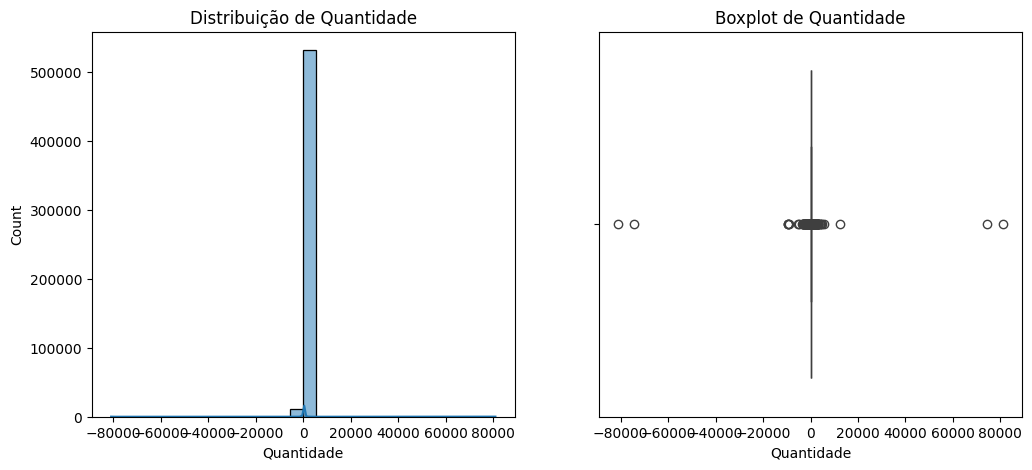

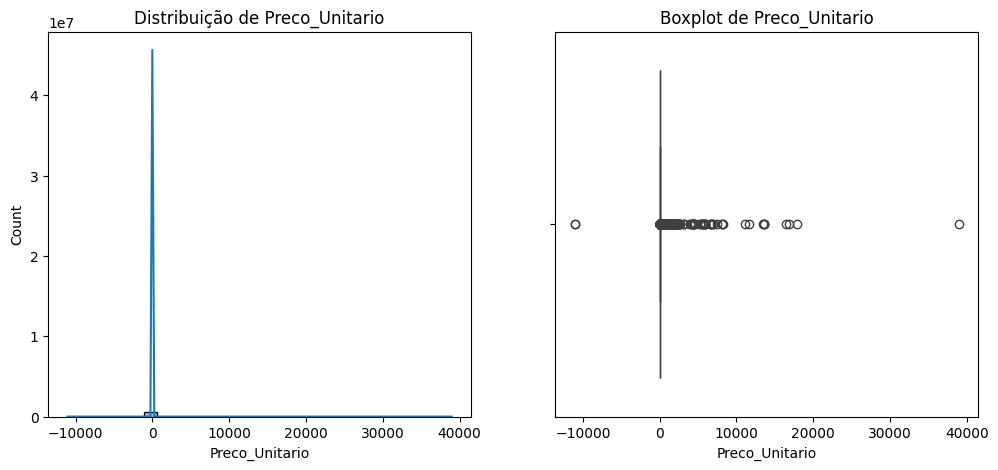

In [ ]:
### ---2. VISUALIZAÇÕES GRÁFICAS--- ###

print("\n----------------------------Gráficos para variáveis numéricas (Histograma e Boxplot): ---------------------------------------")
for col in numerical_cols:
    plt.figure(figsize=(12, 5))

    # Histograma
    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribuição de {col}')

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot de {col}')

    plt.show()

### **3.2.2) Variáveis Categóricas**


Contagem de valores únicos para Variáveis Categóricas: 

N_Fatura:
N_Fatura
573585    1114
581219     749
581492     731
580729     721
558475     705
579777     687
581217     676
537434     675
580730     662
538071     652
580367     650
580115     645
581439     635
580983     629
578344     622
538349     620
578347     606
537638     601
537237     597
576617     593
Name: count, dtype: int64
... (25900 valores únicos no total)


SKU:
SKU
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
22383     1348
22457     1280
23203     1267
POST      1256
22386     1251
22469     1239
22960     1229
21931     1214
22086     1210
22411     1202
Name: count, dtype: int64
... (4070 valores únicos no total)


Descricao:
Descricao
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                        

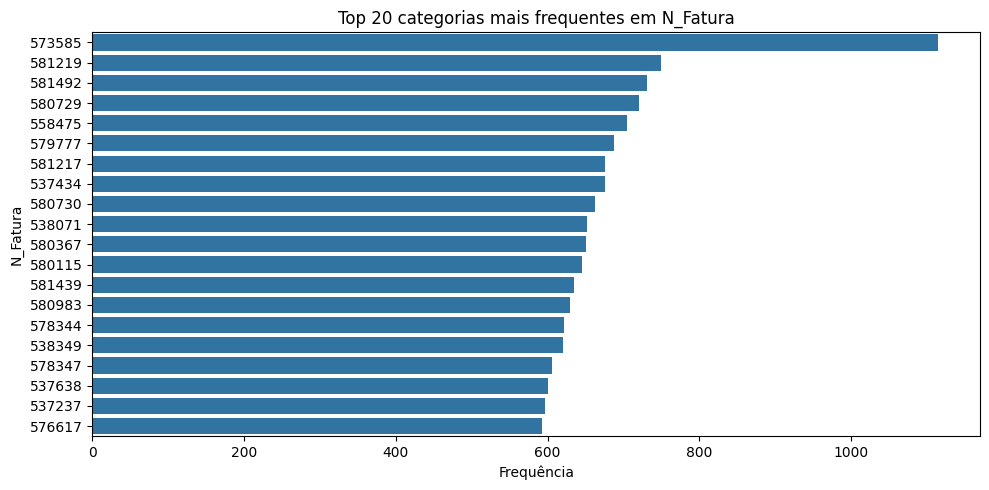

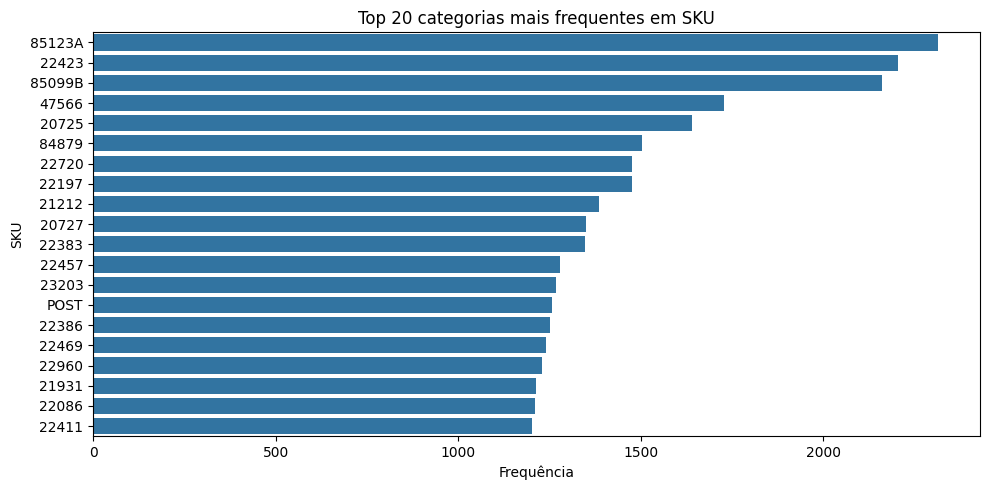

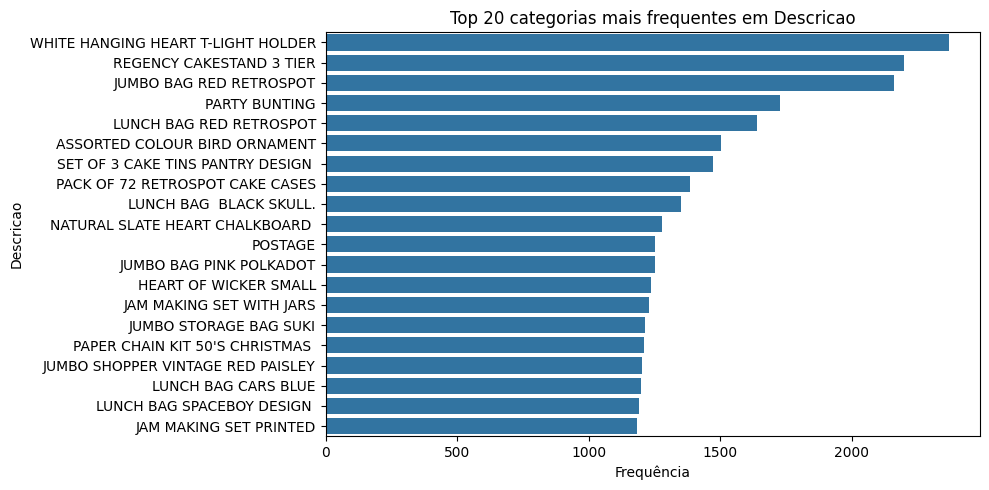

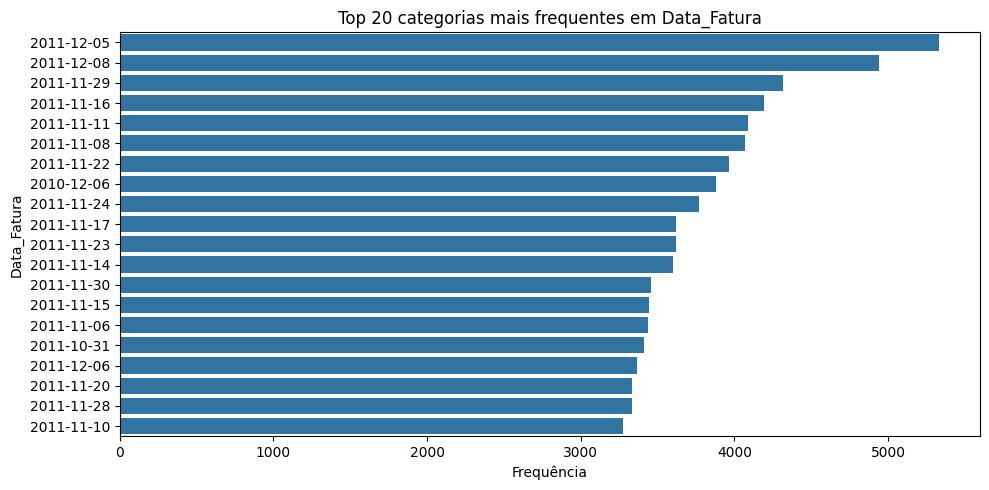

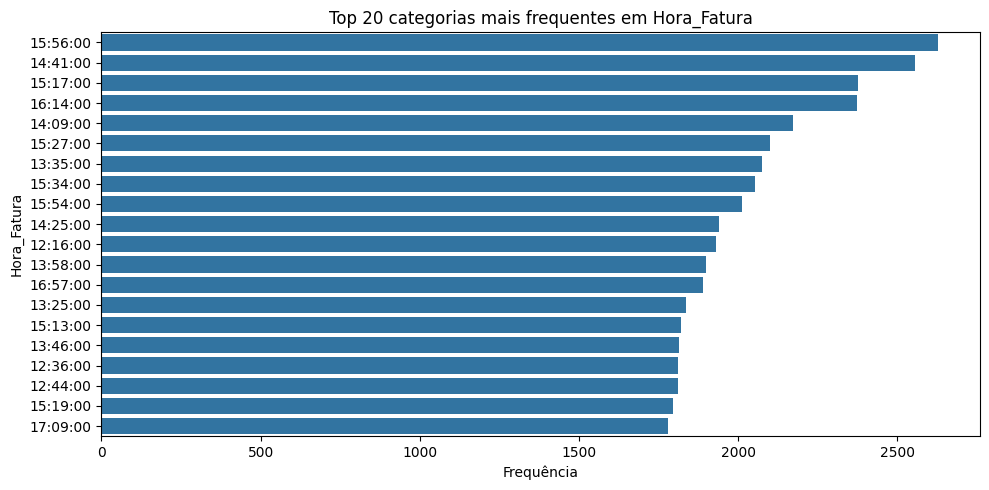

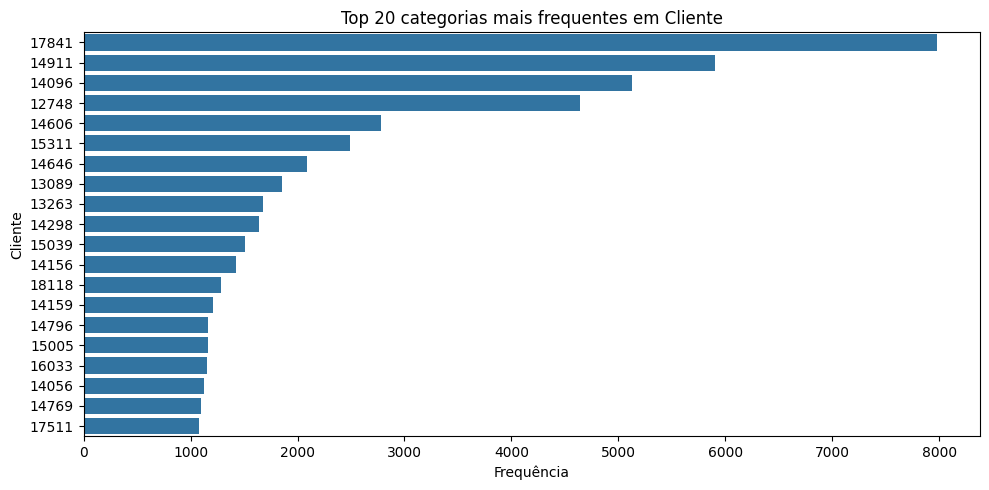

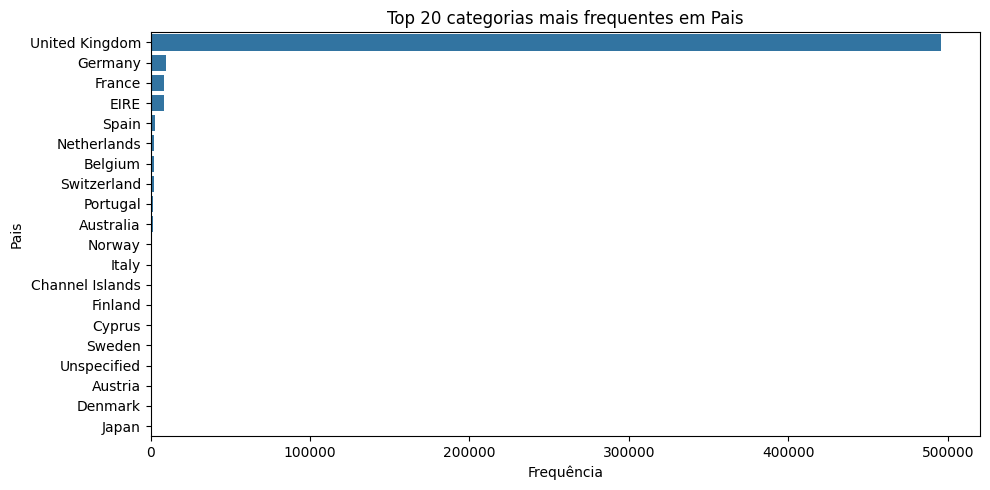

In [ ]:
### ---3.1. ESTATÍSTICAS DESCRITIVAS--- ###

print("\nContagem de valores únicos para Variáveis Categóricas: ")
for col in categorical_cols:
    print(f"\n{col}:")
    value_counts = df[col].value_counts()
    print(value_counts.head(20))  # Mostra só os 20 mais frequentes
    print(f"... ({len(value_counts)} valores únicos no total)\n")



### ---3.2. VISUALIZAÇÕES GRÁFICAS--- ###

print("\n--------------------------Gráficos para variáveis categóricas (Barplot): --------------------------------------------------")
for col in categorical_cols:
    plt.figure(figsize=(10, 5))

    # Barplot
    top_values = df[col].value_counts().nlargest(20)
    sns.barplot(y=top_values.index, x=top_values.values)
    plt.title(f'Top 20 categorias mais frequentes em {col}')
    plt.xlabel('Frequência')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [ ]:
### ---4. OUTRAS ESTATÍSTICAS ESPECÍFICAS--- ###

# -> 4.1.) N_Fatura -> Número real de faturas
print("\n------------------------------------N_Fatura -> Número real de faturas------------------------------------")

total_faturas = df['N_Fatura'].nunique()

total_faturas_anuladas = df.loc[df['N_Fatura'].astype(str).str.startswith('C'), 'N_Fatura'].nunique()

total_faturas_vendas = total_faturas - total_faturas_anuladas

print(f"\nTotal real de faturas: {total_faturas}")

print(f"\nTotal de faturas de vendas válidas: {total_faturas_vendas}")
print(f"Total de faturas com anulações: {total_faturas_anuladas}")

print(f"\nPercentagem de faturas de vendas válidas: {(total_faturas_vendas / total_faturas) * 100:.2f}%")
print(f"Percentagem de faturas com anulações: {(total_faturas_anuladas/ total_faturas) * 100:.2f}%")



# -> 4.2.) N_Fatura -> Vendas reais
print("\n------------------------------------N_Fatura -> Vendas reais------------------------------------")

quantidade_registos_vendas = (~df['N_Fatura'].astype(str).str.startswith('C')).sum()

print(f"\nNúmero de registos com faturas reais: {quantidade_registos_vendas}")
print(f"Percentagem de registos de venda: {(quantidade_registos_vendas / len(df)) * 100:.2f}%")



# -> 4.3.) N_Fatura -> Anulações
print("\n------------------------------------N_Fatura -> Anulações------------------------------------")

quantidade_registo_anulacoes = df['N_Fatura'].astype(str).str.startswith('C').sum()

print(f"\nNúmero de registos com faturas anuladas: {quantidade_registo_anulacoes}")
print(f"Percentagem de registos de anulações: {(quantidade_registo_anulacoes / len(df)) * 100:.2f}%")



# -> 4.4.) SKU
print("\n------------------------------------SKU------------------------------------")

sku_dif = df['SKU'].nunique()
faturas_corretas_5 = df[df['SKU'].astype(str).str.match(r'^\d{5}')].shape[0]
faturas_unicas_5 = df[df['SKU'].astype(str).str.match(r'^\d{5}')]['SKU'].nunique()

print(f"\nNúmero de SKU únicos: {sku_dif}")
print(f"\nTotal de SKU com 5 dígitos: {faturas_corretas_5}")
print(f"\nNúmero de SKU únicos com 5 dígitos: {faturas_unicas_5}")



# -> 4.5.) Descricao
print("\n------------------------------------Descricao------------------------------------")

descricoes_com_minusculas = df['Descricao'].astype(str).str.contains(r'[a-z]', regex=True).sum()

print("\nTotal de descrições que contêm minúsculas:", descricoes_com_minusculas)



# -> 4.6.) Preco_Unitario
print("\n------------------------------------Preco_Unitario------------------------------------")

preco_zero = df[df['Preco_Unitario'] == 0]
print("\nTotal de registos com preço unitário zero:", len(preco_zero))
print("Total de faturas com preço unitário zero:", preco_zero['N_Fatura'].nunique())



# -> 4.7.) Data_Fatura
print("\n------------------------------------Data_Fatura------------------------------------")

print("\nData mínima:", df['Data_Fatura'].min())
print("Data máxima:", df['Data_Fatura'].max())



# -> 4.8.) Hora_Fatura
print("\n------------------------------------Hora_Fatura------------------------------------")

print("\nHora mínima:", df['Hora_Fatura'].min())
print("Hora máxima:", df['Hora_Fatura'].max())



# -> 4.9.) Cliente
print("\n------------------------------------Cliente------------------------------------")

df.replace('nan', np.nan, inplace=True)

cliente_sem_nr = df[df['Cliente'].isna()]

total_faturas_vendas_sem_cliente = cliente_sem_nr[~cliente_sem_nr['N_Fatura'].astype(str).str.startswith('C')]['N_Fatura'].nunique()
total_faturas_anuladas_sem_cliente = cliente_sem_nr[cliente_sem_nr['N_Fatura'].astype(str).str.startswith('C')]['N_Fatura'].nunique()

print("\nTotal de registos -> SEM NR CLIENTE", cliente_sem_nr.shape[0])
print("Total de faturas -> SEM NR CLIENTE", total_faturas_vendas_sem_cliente + total_faturas_anuladas_sem_cliente)
print("Total de faturas de vendas válidas -> SEM NR CLIENTE:", total_faturas_vendas_sem_cliente)
print("Total de faturas de anulações -> SEM NR CLIENTE:", total_faturas_anuladas_sem_cliente)



------------------------------------N_Fatura -> Número real de faturas------------------------------------

Total real de faturas: 25900

Total de faturas de vendas válidas: 22064
Total de faturas com anulações: 3836

Percentagem de faturas de vendas válidas: 85.19%
Percentagem de faturas com anulações: 14.81%

------------------------------------N_Fatura -> Vendas reais------------------------------------

Número de registos com faturas reais: 532621
Percentagem de registos de venda: 98.29%

------------------------------------N_Fatura -> Anulações------------------------------------

Número de registos com faturas anuladas: 9288
Percentagem de registos de anulações: 1.71%

------------------------------------SKU------------------------------------

Número de SKU únicos: 4070

Total de SKU com 5 dígitos: 538914

Número de SKU únicos com 5 dígitos: 4037

------------------------------------Descricao------------------------------------

Total de descrições que contêm minúsculas: 4490



# **4. Feature Engineering**

### **4.1) Data Cleaning**

In [ ]:
### ---1. CRIAÇÃO DE df_limpo--- ###

df_limpo = df.copy() # cópia criada para o tratamento de dados, preservando a estrutura do df original

**Missing Values:**
- ***'Descricao'*** -> estes valores nulos são apagados com o tratamento de dados que constituem ruído e com o tratamento de dados duplicados
- ***'Cliente'*** -> tendo em conta que os NaN têm uma distribuição heterogénea, tanto em termos de fatura de venda / anulação como
de Data, Hora ou País, presumimos que estes missing values representam clientes sem fidelidade à loja, isto é, sem um cartão ou
número de cliente daquela loja. Assim, decidimos apagar as samples com missing value da coluna 'Cliente'.


**Duplicates:**
- temos 5268 duplicados, aos quais podemos dar drop, porque não acrescentam informação relevante para o modelo de recomendação.


**Tratamento de dados que constituem ruído para o modelo:**
- ***'N_Fatura'*** -> dar drop às faturas que começam por 'C', já que estas constituem anulações, não vendas válidas de produtos.
- ***'SKU'*** -> manter apenas os SKU que começam por 5 caracteres numéricos.
- ***'Descricao'*** -> dar drop às samples em que a descrição contém letras minúsculas, já que, provavelmente, correspondem a erros de introdução manual.
- ***'Preco_Unitario'*** > 0 -> dar drop porque não constitui uma venda válida ou relevante para o sistema.


In [ ]:
### ---2.1. MISSING VALUES--- ###
df_limpo = df_limpo.dropna(subset=["Cliente"])


### ---2.2. DUPLICATES--- ###
df_limpo = df_limpo.drop_duplicates()


### ---2.3. DADOS IRRELEVANTES--- ###
df_limpo = df_limpo[~df_limpo['N_Fatura'].astype(str).str.startswith('C')]
df_limpo = df_limpo[df_limpo['SKU'].astype(str).str.match(r'^\d{5}')]
df_limpo = df_limpo[~df_limpo['Descricao'].astype(str).str.contains(r'[a-z]', regex=True)]
df_limpo = df_limpo[df_limpo['Preco_Unitario'] > 0]


print("Tratamento de Dados concluído.")

Tratamento de Dados concluída.


In [ ]:
### ---3. ANÁLISE DATASET PÓS TRATAMENTO DE DADOS--- ###

print("-----ANÁLISE DATASET PÓS TRATAMENTO DE DADOS-----")

print("\n-----Forma do dataset-----")
print(df_limpo.shape)

print("\n-----Dados descritivos do dataset-----")
print(df_limpo.describe())

print("\n-----Duplicados do dataset-----")
print(df_limpo.duplicated().sum())

print("\n-----Nulos por coluna-----")
print(df_limpo.isnull().sum())

print("\n-----Total de nulos-----")
print(df_limpo.isnull().sum().sum())

-----ANÁLISE DATASET PÓS TRATAMENTO DE DADOS-----

-----Forma do dataset-----
(389795, 9)

-----Dados descritivos do dataset-----
          Quantidade                    Data_Fatura  Preco_Unitario
count  389795.000000                         389795   389795.000000
mean       13.122541  2011-07-10 05:13:05.923883264        2.877057
min         1.000000            2010-12-01 00:00:00        0.040000
25%         2.000000            2011-04-07 00:00:00        1.250000
50%         6.000000            2011-07-31 00:00:00        1.950000
75%        12.000000            2011-10-20 00:00:00        3.750000
max     80995.000000            2011-12-09 00:00:00      649.500000
std       180.983645                            NaN        4.287288

-----Duplicados do dataset-----
0

-----Nulos por coluna-----
N_Fatura          0
SKU               0
Descricao         0
Quantidade        0
Data_Fatura       0
Hora_Fatura       0
Preco_Unitario    0
Cliente           0
Pais              0
dtype: int64

-

### **4.2) Novo df orientado aos clientes**

Antes de avançar para a construção de um df orientado aos clientes, vamos acrescentar novas features ao df_limpo que nos ajudarão a extrair informação útil:
- ***'Indice_Dia_Fatura'*** -> útil para ver a tendência de compra ao longo do tempo
- ***'Mes_fatura'*** -> útil para fazer cálculos mensais
- ***'Dia_da_semana'*** -> útil para extrair o dia favorito de compras de cada cliente
- ***'Intervalo_Hora_Fatura'*** -> útil para extrair o horário favorito de compras de cada cliente (separado em 24 bins hora a hora)

In [ ]:
### ---1.1. ACRESCENTAR FEATURES AO df_limpo--- ###

df_limpo['Indice_Dia_Fatura'] = (df_limpo['Data_Fatura'] - df_limpo['Data_Fatura'].min()).dt.days                          # índice do dia da fatura

df_limpo['Mes_Fatura'] = df_limpo['Data_Fatura'].dt.to_period('M')                                                         # mês da fatura

df_limpo['Dia_da_Semana'] = df_limpo['Data_Fatura'].dt.day_name()                                                          # dia da semana

df_limpo['Intervalo_Hora_Fatura'] = df_limpo['Hora_Fatura'].apply(lambda x: f"{x.hour:02d}:00-{(x.hour + 1)%24:02d}:00")   # intervalo da hora da compra


### ---1.2. REORGANIZAR A ORDEM DAS COLUNAS--- ###

colunas = list(df_limpo.columns)
colunas.insert(colunas.index('Data_Fatura') + 1, colunas.pop(colunas.index('Indice_Dia_Fatura')))
colunas.insert(colunas.index('Indice_Dia_Fatura') + 1, colunas.pop(colunas.index('Mes_Fatura')))
colunas.insert(colunas.index('Mes_Fatura') + 1, colunas.pop(colunas.index('Dia_da_Semana')))
colunas.insert(colunas.index('Hora_Fatura') + 1, colunas.pop(colunas.index('Intervalo_Hora_Fatura')))
df_limpo = df_limpo[colunas]

**Features orientadas aos clientes (armazenadas em df_clientes, criado abaixo):**

  + número de dias desde a última compra
  + intervalo de tempo médio entre compras (em dias)
  + dia da semana preferido para compra
  + hora do dia preferido para a compra
  + número total de compras
  + quantia total gasta
  + número total de produtos distintos comprados
  + gasto médio por compra
  + número médio de produtos por compra
  + gasto médio mensal
  + desvio padrão do gasto mensal
  + representação numérica da tendência de compra ao longo do período histórico

In [ ]:
### ---2. NOVO DATAFRAME ORIENTADO AOS CLIENTES--- ###

df_clientes = pd.DataFrame(df_limpo['Cliente'].unique(), columns=['Cliente'])

In [ ]:
### ---3. NOVAS FEATURES--- ###

# -> 3.1) Dias desde a última compra

data_referencia = pd.to_datetime('2011-12-09')

dias_ultima_compra = (df_limpo.groupby('Cliente')['Data_Fatura'].max().apply(lambda data: (data_referencia - data).days))

df_clientes['Dias_Ultima_Compra'] = df_clientes['Cliente'].map(dias_ultima_compra)



# -> 3.2) Intervalo de dias desde a última compra

intervalo_medio = (df_limpo.groupby('Cliente')['Data_Fatura'].apply(lambda s: s.diff().dt.days.mean()).round(2))

df_clientes['Intervalo_medio_entre_compras'] = df_clientes['Cliente'].map(intervalo_medio).fillna(0) # para além do mapeamento, acrescentamos o .fillna(0) para substituir os NaN por zeros. os NaN representavam clientes que só foram às compras uma vez, por isso era impossível calcular o desvio padrão



# -> 3.3) Dia da semana preferido para compra por cliente

faturas_unicas = df_limpo.drop_duplicates(subset=['Cliente', 'N_Fatura']) # Selecionar apenas uma linha por fatura (por cliente)

dias_por_cliente = (faturas_unicas.groupby(['Cliente', 'Dia_da_Semana']).size().reset_index(name='Total')) # Contar o número de faturas por cliente e dia da semana

dia_preferido = (dias_por_cliente.sort_values(['Cliente', 'Total'], ascending=[True, False])
    .drop_duplicates('Cliente')
    .set_index('Cliente')['Dia_da_Semana']) # Obter o dia mais frequente por cliente

df_clientes['Dia_com_mais_faturas'] = df_clientes['Cliente'].map(dia_preferido)



# -> 3.4) Hora do dia preferido para a compra

faturas_unicas = df_limpo.drop_duplicates(subset=['Cliente', 'N_Fatura']) # Selecionar apenas uma linha por fatura (única por cliente)

intervalos_por_cliente = (faturas_unicas.groupby(['Cliente', 'Intervalo_Hora_Fatura']).size().reset_index(name='Total')) # Contar faturas por cliente e intervalo


intervalo_preferido = (intervalos_por_cliente.sort_values(['Cliente', 'Total'], ascending=[True, False])
    .drop_duplicates('Cliente')
    .set_index('Cliente')['Intervalo_Hora_Fatura']) # Obter o intervalo mais frequente por cliente

df_clientes['Intervalo_favorito'] = df_clientes['Cliente'].map(intervalo_preferido)



# -> 3.5) Número total de compras

total_produtos_por_cliente = (df_limpo.groupby('Cliente')['Quantidade'].sum()) # Contar o número total de quantidades por cliente

df_clientes['Total_Compras'] = df_clientes['Cliente'].map(total_produtos_por_cliente)



# -> 3.6) Valor total gasto por cliente

gasto_total_por_cliente = ((df_limpo['Preco_Unitario'] * df_limpo['Quantidade'])
    .groupby(df_limpo['Cliente'])
    .sum()
    .round(2)) # Calcular o total gasto por cliente sem alterar df_limpo

df_clientes['Total_gasto'] = df_clientes['Cliente'].map(gasto_total_por_cliente)



# -> 3.7) Número total de produtos distintos comprados

skus_unicos_por_cliente = df_limpo.groupby('Cliente')['SKU'].nunique() # Contar o número de SKUs únicos por cliente

df_clientes['Total_Produtos_Distintos'] = df_clientes['Cliente'].map(skus_unicos_por_cliente)



# -> 3.8) Gasto médio por compra

total_faturas_por_cliente = (df_limpo.drop_duplicates(subset=['Cliente', 'N_Fatura']).groupby('Cliente').size()) # Contar o número de faturas únicas por cliente

df_clientes['Gasto_Medio_Fatura'] = (df_clientes['Total_gasto'] / df_clientes['Cliente'].map(total_faturas_por_cliente)).round(2)



# -> 3.9) Número médio de produtos por compra

produtos_por_fatura = (df_limpo.groupby(['Cliente', 'N_Fatura'])['SKU'].nunique())

media_produtos_por_cliente = (produtos_por_fatura.groupby('Cliente').mean().round(2))

df_clientes['N_Produtos_Media'] = df_clientes['Cliente'].map(media_produtos_por_cliente)



# -> 3.10) Gasto médio mensal

gasto_mensal_por_cliente = (df_limpo
    .assign(Gasto = df_limpo['Preco_Unitario'] * df_limpo['Quantidade'])
    .groupby(['Cliente', 'Mes_Fatura'])['Gasto']
    .sum())

gasto_medio_mensal = (gasto_mensal_por_cliente
    .groupby('Cliente')
    .mean()
    .round(2))

df_clientes['Gasto_Medio_Mensal'] = df_clientes['Cliente'].map(gasto_medio_mensal)



# -> 3.11) Desvio padrão do gasto mensal

gasto_mensal_por_cliente = (df_limpo
    .assign(Gasto = df_limpo['Preco_Unitario'] * df_limpo['Quantidade'])
    .groupby(['Cliente', 'Mes_Fatura'])['Gasto']
    .sum())

desvio_gasto_mensal = (gasto_mensal_por_cliente
    .groupby('Cliente')
    .std()
    .round(2))

df_clientes['Desvio_Gasto_Mensal'] = df_clientes['Cliente'].map(desvio_gasto_mensal).fillna(0) # para além do mapeamento, acrescentamos o .fillna(0) para substituir os NaN por zeros. os NaN representavam clientes que só foram às compras uma vez, por isso era impossível calcular o desvio padrão



# -> 3.12) Representação numérica da tendência de compra ao longo do período histórico

def calcular_tendencia(cliente_df):
    dias = cliente_df['Indice_Dia_Fatura'].values
    gasto = (cliente_df['Preco_Unitario'] * cliente_df['Quantidade']).values

    if len(np.unique(dias)) < 2:
        return 0 # Se houver menos de 2 dias distintos, não dá para regressão

    slope, intercept, r_value, p_value, std_err = linregress(dias, gasto)
    return slope # o slope é o m da equação da reta, o declive

tendencias = df_limpo.groupby('Cliente').apply(calcular_tendencia).round(4)

df_clientes['Tendencia_Compra'] = df_clientes['Cliente'].map(tendencias)


/tmp/ipython-input-144666418.py:145: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tendencias = df_limpo.groupby('Cliente').apply(calcular_tendencia).round(4)


In [ ]:
### ---4. ANÁLISE DATASET df_clientes--- ###

df_clientes.head(10)

,Cliente,Dias_Ultima_Compra,Intervalo_medio_entre_compras,Dia_com_mais_faturas,Intervalo_favorito,Total_Compras,Total_gasto,Total_Produtos_Distintos,Gasto_Medio_Fatura,N_Produtos_Media,Gasto_Medio_Mensal,Desvio_Gasto_Mensal,Tendencia_Compra
0,17850,372,0.00,Thursday,09:00-10:00,1733,5391.21,21,158.56,8.74,5391.21,0.00,0.4224
1,13047,56,1.86,Wednesday,08:00-09:00,1390,3232.59,105,359.18,19.00,461.80,71.05,-0.0104
2,12583,2,1.61,Friday,12:00-13:00,5028,6705.38,114,447.03,15.47,558.78,264.73,-0.0153
3,13748,95,10.30,Monday,09:00-10:00,439,948.25,24,189.65,5.60,316.08,97.18,-0.2282
4,15100,333,20.00,Wednesday,09:00-10:00,80,876.00,1,292.00,1.00,438.00,371.66,-4.6711
5,15291,25,3.48,Friday,09:00-10:00,2092,4608.80,60,329.20,7.21,658.40,182.05,0.0424
6,14688,7,1.13,Tuesday,12:00-13:00,3584,5579.10,148,265.67,15.29,464.92,107.34,0.0112
7,17809,16,5.95,Friday,12:00-13:00,2057,5411.91,46,450.99,5.08,676.49,688.80,-0.0912
8,15311,0,0.16,Friday,13:00-14:00,38120,60599.00,566,665.92,25.82,4661.46,1913.71,0.0076
9,16098,87,4.33,Tuesday,09:00-10:00,613,2005.63,34,286.52,9.43,286.52,106.97,-0.0765


In [ ]:
### ---5. ANÁLISE DATASET df_clientes--- ###

print("-----ANÁLISE DATASET df_clientes-----")

print("\n-----Forma do dataset-----")
print(df_clientes.shape)

print("\n-----Tipo de dados do dataset-----")
print(df_clientes.dtypes)

print("\n-----Dados descritivos do dataset-----")
print(df_clientes.describe())

print("\n-----Duplicados do dataset-----")
print(df_clientes.duplicated().sum())

print("\n-----Nulos por coluna-----")
print(df_clientes.isnull().sum())

print("\n-----Total de nulos-----")
print(df_clientes.isnull().sum().sum())

-----ANÁLISE DATASET df_clientes-----

-----Forma do dataset-----
(4333, 13)

-----Tipo de dados do dataset-----
Cliente                           object
Dias_Ultima_Compra                 int64
Intervalo_medio_entre_compras    float64
Dia_com_mais_faturas              object
Intervalo_favorito                object
Total_Compras                      int64
Total_gasto                      float64
Total_Produtos_Distintos           int64
Gasto_Medio_Fatura               float64
N_Produtos_Media                 float64
Gasto_Medio_Mensal               float64
Desvio_Gasto_Mensal              float64
Tendencia_Compra                 float64
dtype: object

-----Dados descritivos do dataset-----
       Dias_Ultima_Compra  Intervalo_medio_entre_compras  Total_Compras  \
count         4333.000000                    4333.000000    4333.000000   
mean            92.199862                       3.228209    1180.498731   
std            100.142289                      10.529051    5032.422961   


# **5. Clustering**

O objetivo desta etapa é segmentar os clientes com base no seu comportamento de compra, utilizando *clustering*, não supervisionado. Pretendíamos obter grupos de clientes homogéneos internamente e distintos entre si, de forma a apoiar decisões de *marketing* e servir de base ao sistema de recomendação.

**Escolha inicial do número de clusters (Elbow Method):**  

Numa primeira abordagem, aplicámos diretamente o método do *Elbow* sobre os dados escalados. No entanto, o gráfico não apresentava um “cotovelo” bem definido, aproximando-se de uma linha quase contínua. Isto dificultou a tarefa de identificarmos um valor ótimo para *k*, levantando hipóteses de que a estrutura dos dados estivesse a ser afetada por outros fatores.

---

**Hipótese 1 – Redução de dimensionalidade (PCA)**  

A nossa primeira hipótese foi que a dimensionalidade do espaço de *features* (10) pudesse estar a dificultar a identificação de clusters bem definidos. Aplicámos então o *Principal Component Analysis (PCA)* como técnica de redução de dimensionalidade.

Inicialmente, testámos o PCA com **1 componente**, uma vez que esta já explicava uma percentagem muito elevada da variância total dos dados (`[0.98403526%]`). Posteriormente, utilizámos **2 componentes**, sobretudo com o objetivo de permitir a visualização gráfica dos clusters em 2D. De notar que quando aplicamos PCA com `n_components=2` a segunda componente praticamente não influenciava a variância (`[0.00884511%]`).

No entanto, ao repetir o método do *Elbow* após o PCA, verificámos que os resultados se mantinham praticamente inalterados, não resolvendo o problema inicial. Isto indicou que a dimensionalidade, por si só, não era a principal causa da dificuldade na segmentação.

---

**Hipótese 2 – Presença de outliers**  

A segunda hipótese levantada foi a existência de *outliers* significativos, capazes de distorcer as distâncias utilizadas pelo algoritmo K-Means. Para validar esta hipótese, analisámos a distribuição das *features* através de *boxplots*, confirmando a presença de valores extremos, sobretudo do lado direito das distribuições.


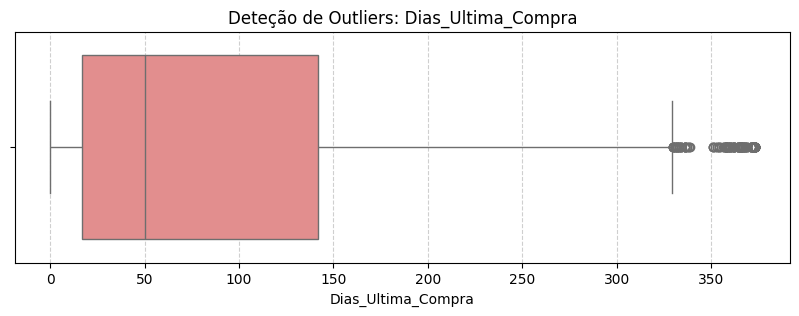

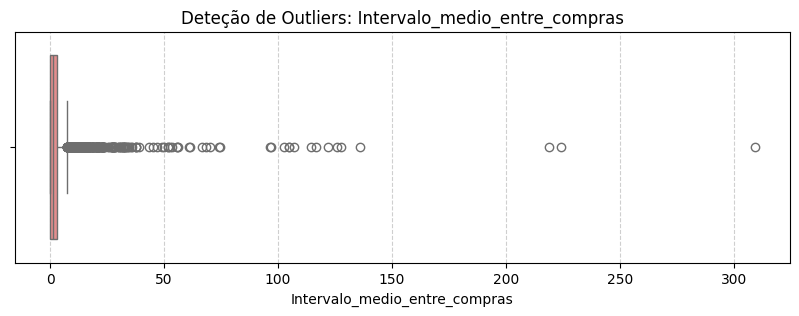

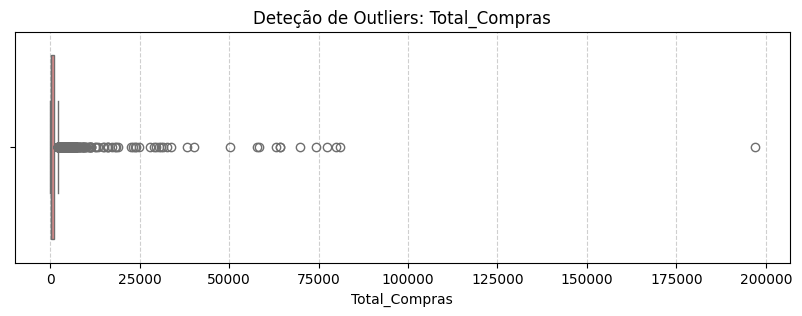

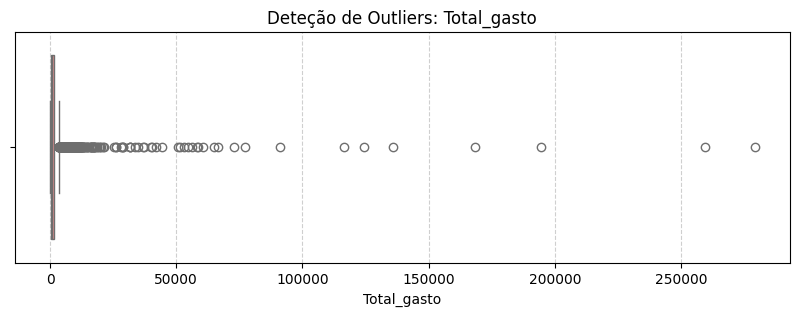

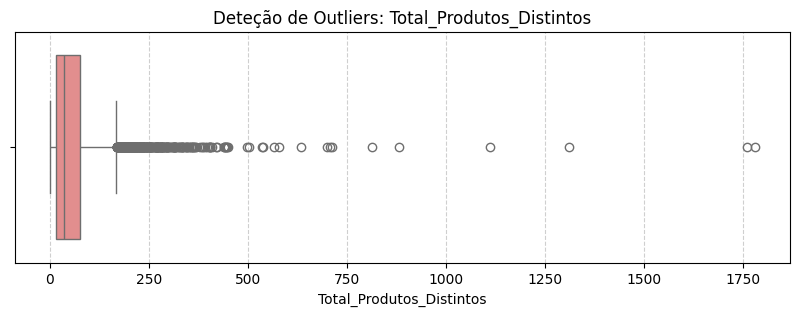

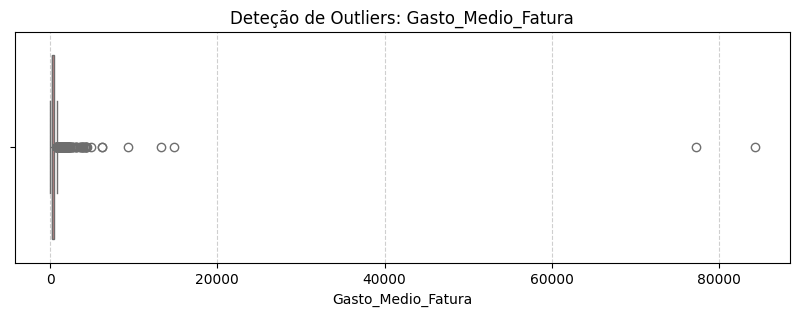

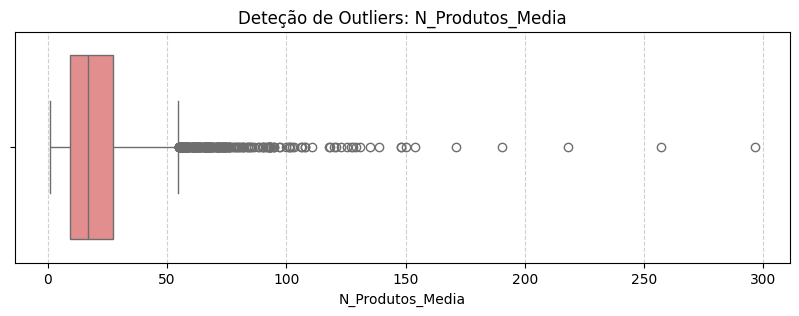

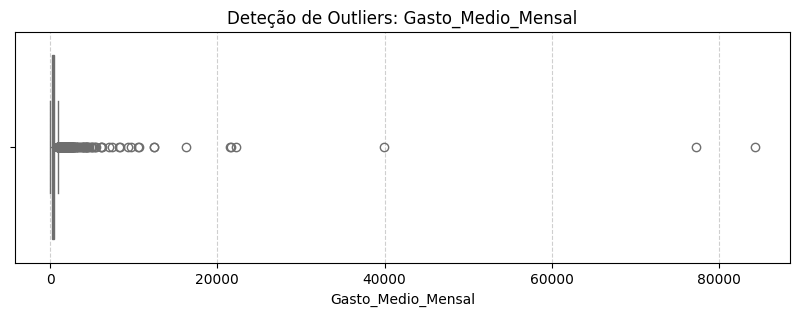

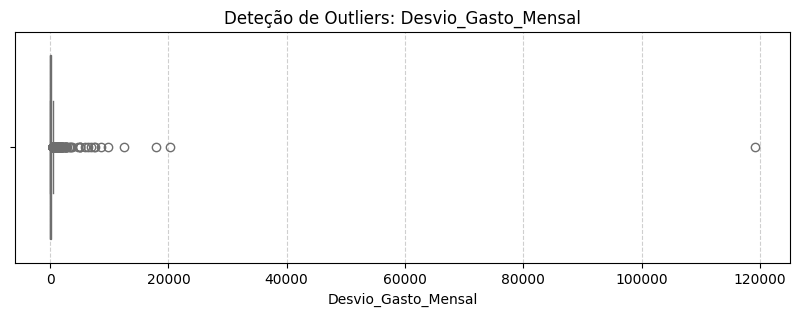

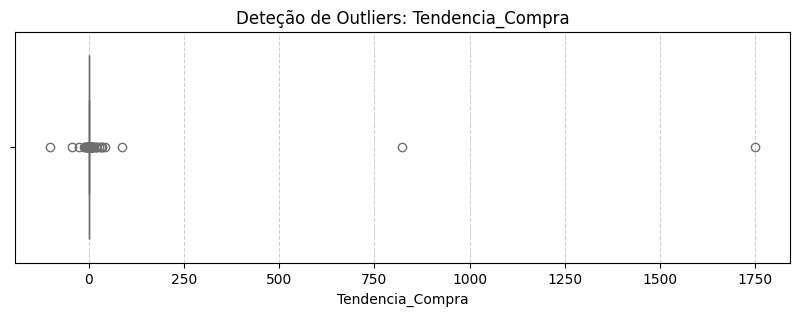

In [ ]:
### ---1. ANÁLISE DE OUTLIERS - GRÁFICOS--- ###

# Listar as colunas numéricas criadas no df_clientes
features_clientes = [
    'Dias_Ultima_Compra', 'Intervalo_medio_entre_compras', 'Total_Compras',
    'Total_gasto', 'Total_Produtos_Distintos', 'Gasto_Medio_Fatura',
    'N_Produtos_Media', 'Gasto_Medio_Mensal', 'Desvio_Gasto_Mensal', 'Tendencia_Compra'
]

# Boxplots para cada feature
for col in features_clientes:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df_clientes[col], color='lightcoral')
    plt.title(f'Deteção de Outliers: {col}')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.show()

In [ ]:
### ---2. ANÁLISE DE OUTLIERS - ESTATÍSTICAS--- ###

for col in features_clientes:
    Q1 = df_clientes[col].quantile(0.25)
    Q3 = df_clientes[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 3 * IQR
    upper_limit = Q3 + 3 * IQR

    outliers = df_clientes[
        (df_clientes[col] < lower_limit) | (df_clientes[col] > upper_limit)
    ]

    print(f"\n### {col} ###")
    print("Número de outliers:", outliers.shape[0])
    print("Limites IQR:")
    print("Lower:", lower_limit)
    print("Upper:", upper_limit)

    if outliers.shape[0] > 0:
        print("Min / Max dos outliers:")
        print(outliers[col].agg(["min", "max"]))


### Dias_Ultima_Compra ###
Número de outliers: 0
Limites IQR:
Lower: -358.0
Upper: 517.0

### Intervalo_medio_entre_compras ###
Número de outliers: 205
Limites IQR:
Lower: -9.0
Upper: 12.0
Min / Max dos outliers:
min     12.04
max    309.00
Name: Intervalo_medio_entre_compras, dtype: float64

### Total_Compras ###
Número de outliers: 222
Limites IQR:
Lower: -2316.0
Upper: 3459.0
Min / Max dos outliers:
min      3464
max    196844
Name: Total_Compras, dtype: int64

### Total_gasto ###
Número de outliers: 227
Limites IQR:
Lower: -3658.7000000000003
Upper: 5586.27
Min / Max dos outliers:
min      5591.42
max    279138.02
Name: Total_gasto, dtype: float64

### Total_Produtos_Distintos ###
Número de outliers: 113
Limites IQR:
Lower: -167.0
Upper: 260.0
Min / Max dos outliers:
min     262
max    1780
Name: Total_Produtos_Distintos, dtype: int64

### Gasto_Medio_Fatura ###
Número de outliers: 131
Limites IQR:
Lower: -561.24
Upper: 1160.8999999999999
Min / Max dos outliers:
min     1162.65
ma

**Tratamento de outliers**  

Optámos por uma abordagem diferente, adaptada à natureza de cada variável:

- Para a maioria das *features* com distribuições assimétricas à direita (ex.: gastos, quantidades, médias), aplicámos uma **transformação logarítmica**, reduzindo o impacto dos valores extremos sem eliminar informação relevante.
- Para a variável ***'Tendencia_Compra'***, que assumiu valores negativos e positivos (declive de uma regressão), aplicámos um **capping por quantis**, utilizando os limites **0.01 e 0.99**, de forma a conter valores extremos sem distorcer o sinal da tendência.
- Na deteção de outliers via IQR, utilizámos **3 × IQR em vez de 1.5 × IQR**, por se tratar de dados comportamentais reais, onde valores extremos podem representar clientes válidos (ex.: clientes de alto valor) e não erros, sendo mais permissivos:

$$lower limit = Q1 - 3 * IQR$$

$$upper limit = Q3 + 3 * IQR$$

Após este tratamento, voltámos a analisar os *boxplots* e verificámos que as escalas das variáveis se encontravam muito mais equilibradas e comparáveis.

---

**Normalização dos dados**  

Antes de aplicar o *clustering*, normalizamos as variáveis, uma vez que o algoritmo K-Means é sensível à escala dos dados e utiliza distâncias euclidianas.

Optámos por utilizar o **RobustScaler**, em detrimento do **StandardScaler**, pelos seguintes motivos:
- O **StandardScaler** baseia-se na média e no desvio-padrão, sendo altamente sensível a valores extremos.
- Apesar do tratamento de outliers, o conjunto de dados continua a conter clientes com comportamentos naturalmente extremos, que não devem ser tratados como ruído.
- O **RobustScaler** utiliza a mediana e o intervalo interquartil (IQR), tornando-o mais resistente a assimetrias e valores extremos ainda presentes nos dados.

Desta forma, garantimos uma normalização mais estável e representativa do comportamento típico dos clientes, sem distorcer excessivamente a estrutura dos dados.

---

**Novo Elbow Method e escolha de k**  

Com os dados tratados, reaplicámos o método do *Elbow*. Desta vez, o gráfico apresentou um ponto de inflexão claro, indicando que **k = 4** era o número de clusters mais adequado.



In [ ]:
### ---3. TRATAMENTO DE OUTLIERS--- ###

# Log-transform
cols_log = [
    "Intervalo_medio_entre_compras",
    "Total_Compras",
    "Total_gasto",
    "Total_Produtos_Distintos",
    "Gasto_Medio_Fatura",
    "N_Produtos_Media",
    "Gasto_Medio_Mensal",
    "Desvio_Gasto_Mensal"
]

for col in cols_log:
    df_clientes[col] = np.log1p(df_clientes[col])



# Cap por percentil (coluna 'Tendencia_Compra')
lower = df_clientes["Tendencia_Compra"].quantile(0.01)
upper = df_clientes["Tendencia_Compra"].quantile(0.99)

df_clientes["Tendencia_Compra"] = df_clientes["Tendencia_Compra"].clip(lower=lower,upper=upper)



# Normalização dos dados
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df_clientes[features_clientes])


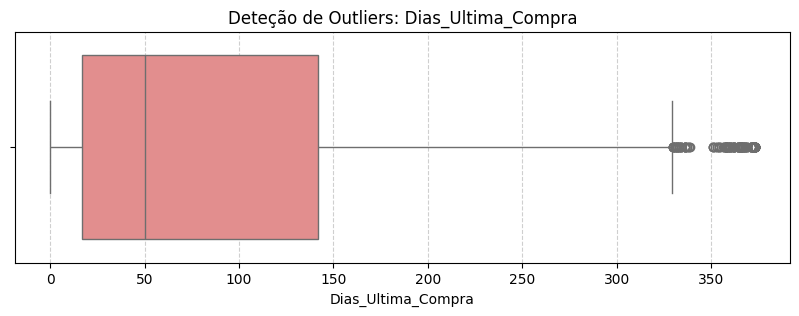

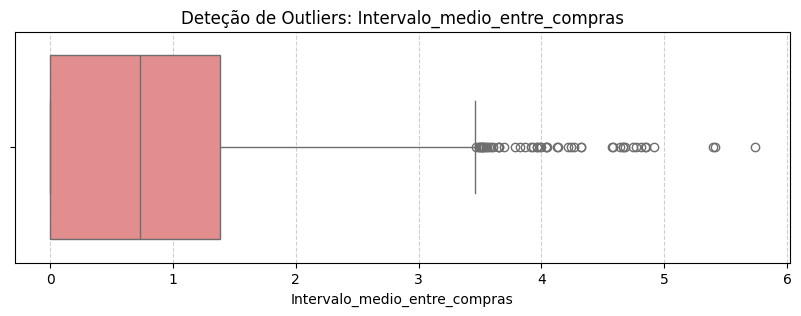

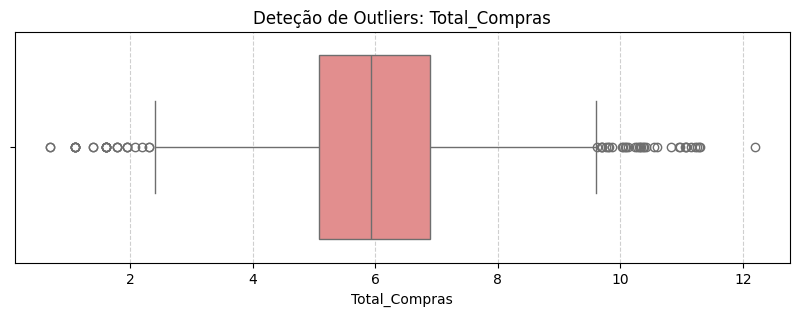

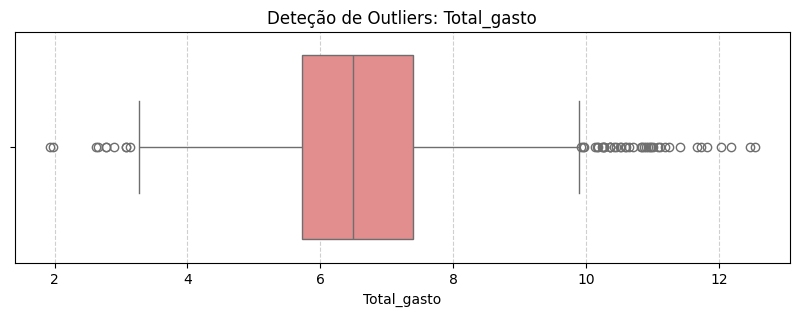

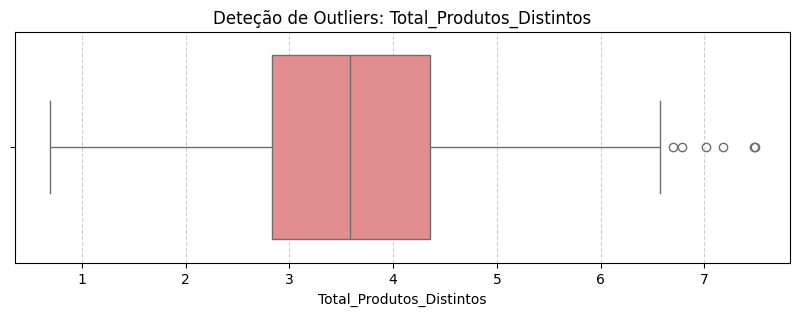

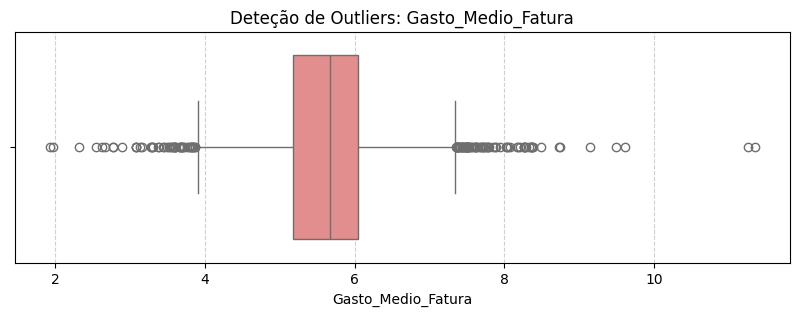

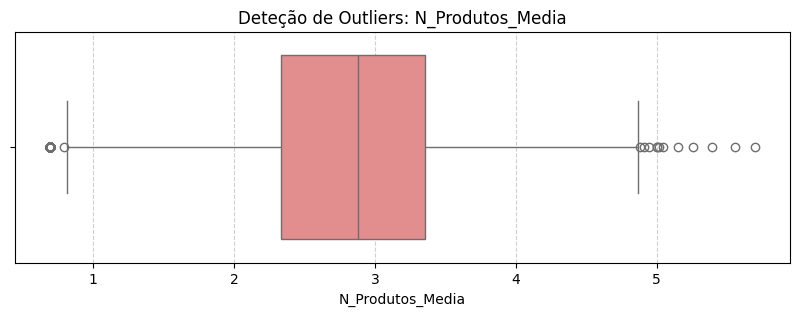

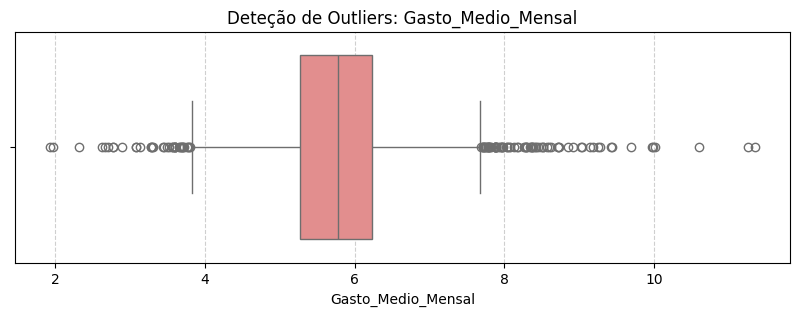

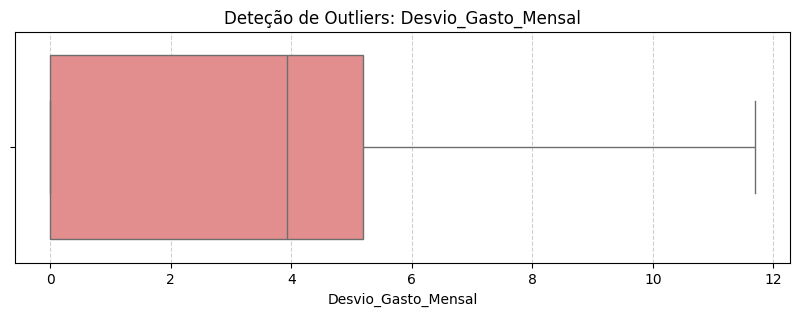

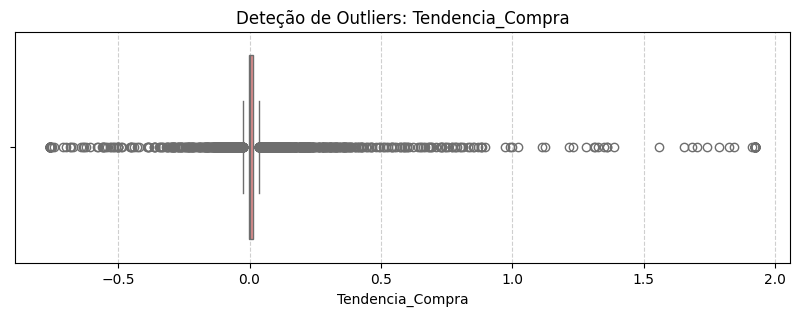

In [ ]:
### ---4. ANÁLISE DE OUTLIERS APÓS O TRATAMENTO - GRÁFICOS--- ###

for col in features_clientes:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df_clientes[col], color='lightcoral')
    plt.title(f'Deteção de Outliers: {col}')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.show()

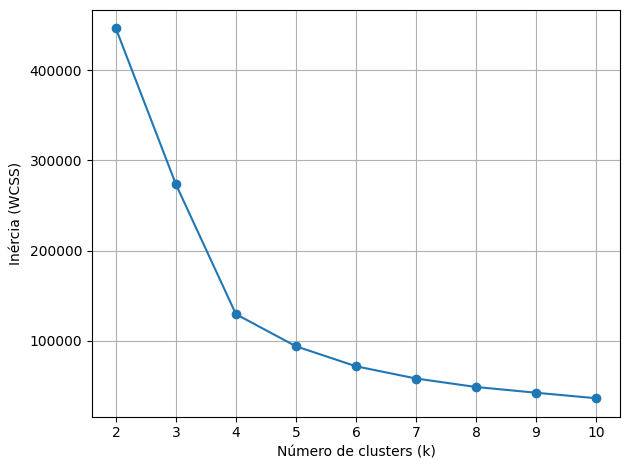

In [ ]:
### ---5. ELBOW METHOD (MÉTODO DO COTOVELO)--- ###

inertias = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, tol=1e-04, random_state=0)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.xticks(k_range)
plt.grid(True)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia (WCSS)')
plt.tight_layout()
plt.show()

**Clustering e reavaliação do PCA**  

Aplicámos o K-Means com **4 clusters**, obtendo uma segmentação estável e interpretável. Voltámos a testar o PCA neste contexto e verificámos que:
- A segunda componente principal explicava uma percentagem muito reduzida da variância (`[0.00884511%]`).
- A estrutura dos clusters e a sua distribuição mantiveram-se inalteradas.

Perante isto, ponderámos as vantagens e desvantagens do PCA:
- **Vantagens:** redução de dimensionalidade e facilitação da visualização.
- **Desvantagens:** perda de interpretabilidade direta das *features*, o que dificulta a análise de perfis de clientes.

Dado que o objetivo principal é a **interpretação e caracterização dos clusters**, optámos por **não utilizar PCA na solução final**, mantendo as variáveis originais.

---

**Análise dos clusters**  

No resultado final, os clusters apresentam a seguinte distribuição de clientes:
- Cluster 0: 4024 clientes  
- Cluster 1: 146 clientes  
- Cluster 2: 100 clientes  
- Cluster 3: 63 clientes  

Para compreender melhor o perfil de cada grupo, analisámos estatísticas descritivas e *boxplots* das principais *features* por cluster. Esta análise permitiu identificar diferenças claras nos padrões de compra, frequência, gasto e diversidade de produtos, validando a qualidade da segmentação obtida.

In [ ]:
### ---6. CLUSTERING COM KMEANS--- ###

# Modelo KMeans
kmeans = KMeans(
    n_clusters=4,
    init='k-means++',   # inicialização para acelerar convergência e melhorar estabilidade
    n_init=10,          # executa o algoritmo 10 vezes com centroides iniciais diferentes
    max_iter=300,
    tol=1e-04,
    random_state=42     # utilizamos o random_state para garantir reprodutibilidade dos resultados
)


cluster_labels = kmeans.fit_predict(X_scaled)
df_clientes['Cluster'] = cluster_labels

print(df_clientes['Cluster'].value_counts())

Cluster
0    4024
2     146
3     100
1      63
Name: count, dtype: int64


Cluster                                        0           1           2  \
Dias_Ultima_Compra            mean     91.634443  120.380952   80.027397   
                              median   50.000000   79.000000   42.500000   
                              min       0.000000    0.000000    0.000000   
                              max     373.000000  366.000000  372.000000   
Intervalo_medio_entre_compras mean      0.802996    1.201771    1.482164   
                              median    0.693147    0.875469    1.177057   
                              min       0.000000    0.029559    0.000000   
                              max       5.736572    4.639572    4.919981   
Total_Compras                 mean      5.959165    5.920417    6.376080   
                              median    5.918894    5.802118    6.249968   
                              min       0.693147    2.890372    3.761200   
                              max      12.190172   11.302180   11.155536   
Total_gasto                   mean      6.546613    6.616555    7.003260   
                              median    6.476172    6.499952    6.708713   
                              min       1.931521    4.149937    3.970292   
                              max      12.539465   12.034534   12.177363   
Total_Produtos_Distintos      mean      3.600130    2.475093    3.051895   
                              median    3.637586    2.564949    3.178054   
                              min       0.693147    0.693147    0.693147   
                              max       7.484930    4.897840    5.003946   
Gasto_Medio_Fatura            mean      5.625545    5.714417    5.793841   
                              median    5.657319    5.689853    5.777153   
                              min       1.931521    3.082369    3.295837   
                              max      11.253955   11.341393    8.348952   
N_Produtos_Media              mean      2.867998    1.918011    2.265015   
                              median    2.908539    1.871802    2.298065   
                              min       0.693147    0.693147    0.693147   
                              max       5.694910    4.248495    4.324133   
Gasto_Medio_Mensal            mean      5.754148    6.112571    6.085502   
                              median    5.758618    6.109870    5.967363   
                              min       1.931521    3.941193    3.295837   
                              max      11.253955   11.341393    9.692513   
Desvio_Gasto_Mensal           mean      2.913699    3.393723    4.716398   
                              median    3.822973    4.070905    5.282883   
                              min       0.000000    0.000000    0.000000   
                              max       9.436052   11.687928    9.921315   
Tendencia_Compra              mean      0.002926    1.800812    0.504501   
                              median    0.000000    1.922740    0.423600   
                              min      -0.298200    1.216700    0.261700   
                              max       0.252500    1.922740    1.125600   

Cluster                                        3  
Dias_Ultima_Compra            mean    114.970000  
                              median   68.500000  
                              min       0.000000  
                              max     360.000000  
Intervalo_medio_entre_compras mean      1.784193  
                              median    1.715596  
                              min       0.009950  
                              max       5.416100  
Total_Compras                 mean      6.306714  
                              median    6.084499  
                              min       3.555348  
                              max      11.068590  
Total_gasto                   mean      6.999075  
                              median    6.743337  
                              min       5.101085  
                              max      12.467122  
Total_Produtos_D

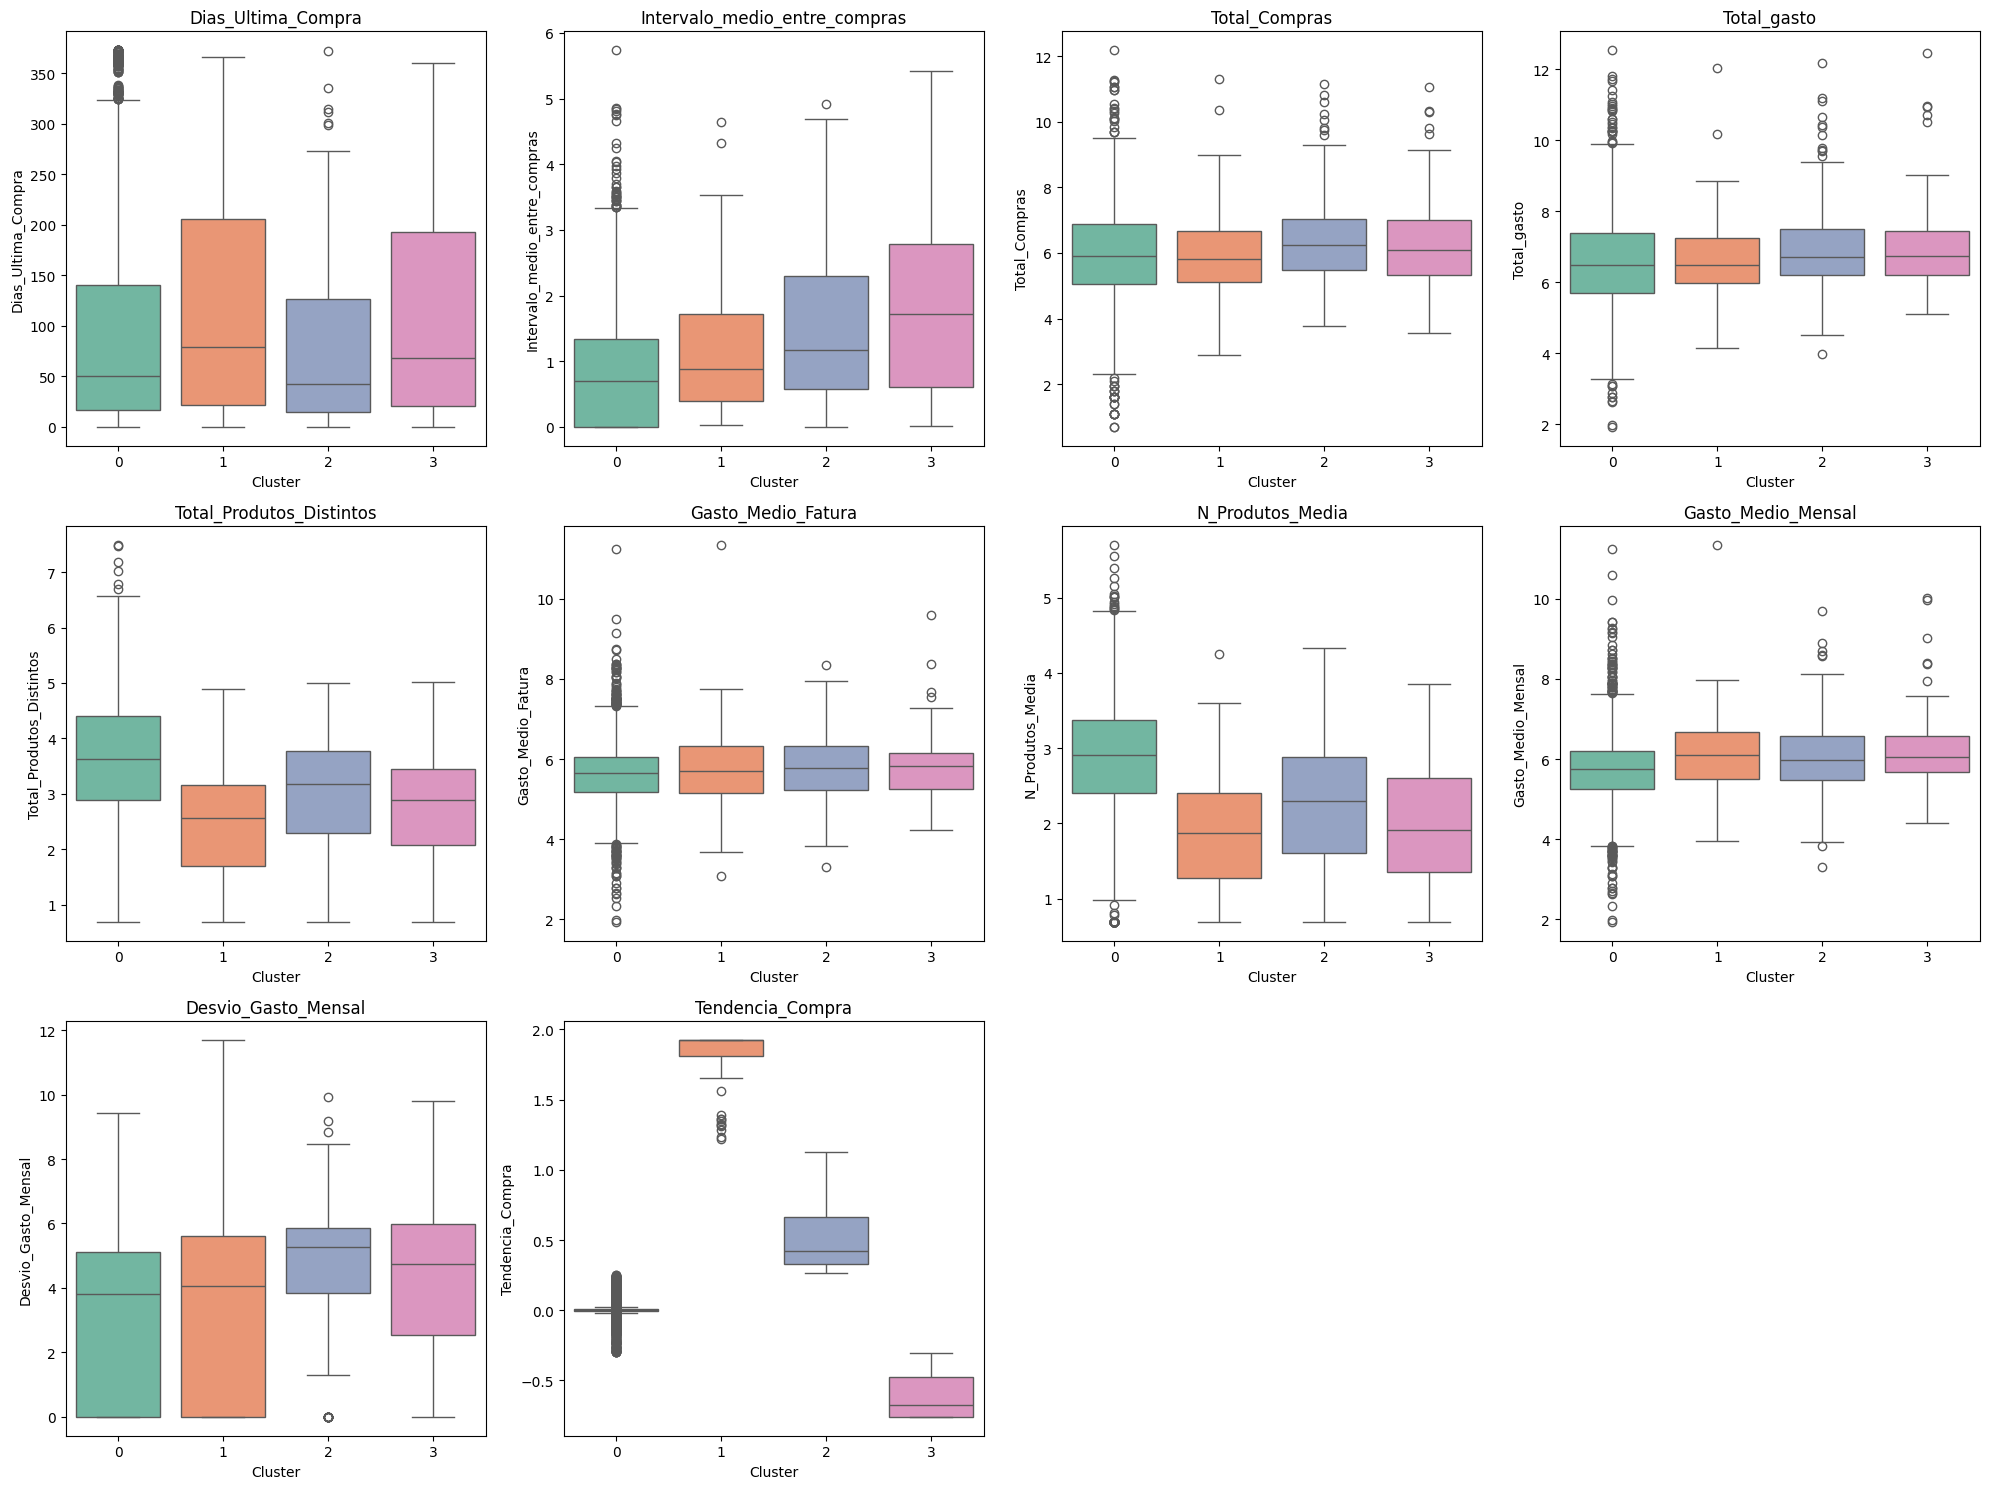

In [ ]:
### ---7. ANÁLISE DOS CLUSTERS--- ###

# Resumo estatístico por cluster (cada cluster por feature de df_clientes)
summary = df_clientes.groupby('Cluster')[features_clientes].agg(['mean', 'median', 'min', 'max']).T
display(summary)

# Boxplots (cada cluster por feature de df_clientes)
plt.figure(figsize=(20, 15))
for i, feature in enumerate(features_clientes):
    plt.subplot(3, 4, i+1)
    sns.boxplot(
        x='Cluster',
        y=feature,
        hue='Cluster',
        data=df_clientes,
        palette='Set2',
        dodge=False,
        legend=False
    )
    plt.title(feature)
    plt.tight_layout()

plt.show()

### **Cluster 0** -> Clientes frequentes em consolidação (≈92% dos clientes)

Este cluster representa a grande maioria dos clientes que compraram durante o período analisado, sendo o perfil dominante da base de clientes. São clientes relativamente frequentes, com intervalos curtos entre compras e boa diversidade de produtos. O gasto médio é estável, mas existe uma elevada variabilidade no gasto mensal, o que indica comportamentos ainda pouco consolidados. No geral, entendemos que se tratam de clientes ativos e envolvidos, mas que ainda não apresentam um padrão de consumo totalmente maduro.

### **Cluster 1** -> Clientes em crescimento (≈3% dos clientes)

Este cluster agrega um número reduzido de clientes, mas com um comportamento bastante distinto. Observamos uma tendência de compra claramente crescente ao longo do tempo. Apesar de apresentarem menor diversidade de produtos e menos itens por fatura, compram com regularidade e mostram sinais fortes de aumento de envolvimento recente. Entendemos este grupo como um segmento pequeno, mas com elevado potencial de evolução.

### **Cluster 2** -> Clientes regulares e estáveis (≈2% dos clientes)

Os clientes deste cluster apresentam um perfil equilibrado e consistente. Percebemos bons níveis de gasto total, uma frequência de compra moderada e crescimento positivo, embora ligeiro e menos acentuado do que no cluster 1. Mantêm estabilidade tanto no número de produtos adquiridos como no gasto médio mensal, refletindo um padrão de consumo previsível e sustentado ao longo do tempo.

### **Cluster 3** -> Clientes em desaceleração (≈1% dos clientes)

Este cluster reúne um conjunto muito reduzido de clientes que apresentam uma tendência de compra negativa. Verificamos intervalos mais longos entre compras e uma diminuição progressiva da atividade, apesar de ainda manterem valores médios de gasto relativamente elevados. Entendemos este grupo como clientes cujo envolvimento com a loja está a diminuir, sendo relevante pensar em como reativá-lo.

# **6. Recommender System**

Com base nos *clusters* obtidos, **desenvolvemos um sistema de recomendação**, orientado ao apoio à tomada de decisão em contextos de *marketing*.

**Criámos um dataset de transações (`df_transacoes`)** que integra apenas a informação essencial para a recomendação: o cliente, o produto adquirido, a quantidade comprada e o *cluster* a que o cliente pertence. Este dataset resulta de um *merge* entre o conjunto de dados original (`df`) e o dataset de clientes segmentados (`df_clientes`), excluindo deliberadamente variáveis que não são relevantes para o objetivo do sistema de recomendação.

De seguida, **analisámos o comportamento de compra de cada *cluster*** através da agregação das quantidades vendidas por produto. Esta análise permite identificar os produtos mais representativos de cada segmento, os produtos mais vendidos. No print em que usamos `.head()` é possível reparar que há produtos que pertencem ao top de vendas de cada *cluster*, mesmo que o volume de vendas (coluna 'Quantidade') seja diferente. Aqui, ao comparar o volume de vendas, é importante ter em atenção o número de clientes por *cluster*.

**Construímos o histórico de compras por cliente**, permitindo identificar os produtos já adquiridos por cada indivíduo. Este passo é fundamental para garantirmos que o sistema não vai recomendar produtos que o cliente já comprou, e assim tornamos as recomendações mais realistas e alinhadas com práticas reais de recomendação.

A lógica do sistema desenvolvido consiste, então, em **recomendar a cada cliente o top 3 (`n_recs=3`) de produtos mais vendidos do seu *cluster* que ainda não fazem parte do seu histórico de compras**. Isto é, não são recomendados os produtos do top 3 do cluster, mas os primeiros 3 produtos mais vendidos por cluster que o cliente ainda não adquiriu. Esta abordagem baseia-se diretamente na segmentação previamente realizada e privilegia a interpretabilidade do modelo, sendo particularmente adequada para campanhas de *marketing* direcionadas e estratégias de *cross-selling*.

No final, **apresentamos um exemplo de recomendações por *cluster***, para um cliente selecionado aleatoriamente.


In [ ]:
### ---1. CRIAÇÃO DE df_transações--- ###

df_transacoes = (
    df_limpo[['Cliente', 'SKU', 'Descricao', 'Quantidade']].merge(
        df_clientes[['Cliente', 'Cluster']],
        on='Cliente',
        how='left'
    )
)

df_transacoes.head()

,Cliente,SKU,Descricao,Quantidade,Cluster
0,17850,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2
1,17850,71053,WHITE METAL LANTERN,6,2
2,17850,84406B,CREAM CUPID HEARTS COAT HANGER,8,2
3,17850,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2
4,17850,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2


In [ ]:
### ---2. ANÁLISE DOS CLUSTERS--- ###

top_produtos_cluster = (
    df_transacoes
    .groupby(['Cluster', 'SKU'], as_index=False)
    .agg({
        'Quantidade': 'sum',
        'Descricao': 'first'
    })
    .sort_values(['Cluster', 'Quantidade'], ascending=[True, False])
)


top_produtos_cluster.groupby('Cluster').head(5)

,Cluster,SKU,Quantidade,Descricao
1983,0,23166,77073,MEDIUM CERAMIC TOP STORAGE JAR
2779,0,84077,35976,WORLD WAR 2 GLIDERS ASSTD DESIGNS
3193,0,85099B,33442,JUMBO BAG RED RETROSPOT
1078,0,22197,30998,SMALL POPCORN HOLDER
3033,0,84879,29123,ASSORTED COLOUR BIRD ORNAMENT
4307,1,23843,80995,"PAPER CRAFT , LITTLE BIRDIE"
4359,1,84077,10753,WORLD WAR 2 GLIDERS ASSTD DESIGNS
3786,1,21915,8412,RED HARMONICA IN BOX
3639,1,16014,8000,SMALL CHINESE STYLE SCISSOR
3913,1,22440,3600,BALLOON WATER BOMB PACK OF 35


In [ ]:
### ---3.1. HISTÓRICO DE COMPRAS POR CLIENTE--- ###

produtos_por_cliente = (
    df_transacoes
    .groupby('Cliente')['SKU']
    .apply(set)
    .to_dict()
)



### ---3.2. FUNÇÃO DE RECOMENDAÇÃO POR CLUSTER--- ###

def recomendar_produtos(cliente_id, df_clientes, top_produtos_cluster, produtos_por_cliente, n_recs=3):

    cluster = df_clientes.loc[
        df_clientes['Cliente'] == cliente_id, 'Cluster'
    ].values[0]

    produtos_cluster = top_produtos_cluster[
        top_produtos_cluster['Cluster'] == cluster
    ].sort_values('Quantidade', ascending=False)['SKU'].tolist()

    ja_comprados = produtos_por_cliente.get(cliente_id, set())

    recomendacoes = []
    for sku in produtos_cluster:
        if sku not in ja_comprados:
            recomendacoes.append(sku)
        if len(recomendacoes) == n_recs:
            break

    return recomendacoes



### ---3.3. EXEMPLOS DE RECOMENDAÇÃO POR CLUSTER--- ###

rows = []

for cluster in sorted(df_clientes['Cluster'].unique()):
    clientes_cluster = df_clientes[df_clientes['Cluster'] == cluster]['Cliente'].tolist()
    cliente_exemplo = random.choice(clientes_cluster)
    recs = recomendar_produtos(cliente_exemplo, df_clientes, top_produtos_cluster, produtos_por_cliente, n_recs=3)

    for pos, sku in enumerate(recs, start=1):
        desc = top_produtos_cluster.loc[top_produtos_cluster['SKU'] == sku, 'Descricao'].values[0]
        rows.append({
            'Cluster': cluster,
            'Cliente': cliente_exemplo,
            'Top_Produto': pos,
            'Produto': sku,
            'Descricao': desc
        })


df_recomendacoes = pd.DataFrame(rows)
df_recomendacoes

,Cluster,Cliente,Top_Produto,Produto,Descricao
0,0,14995,1,23166,MEDIUM CERAMIC TOP STORAGE JAR
1,0,14995,2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS
2,0,14995,3,85099B,JUMBO BAG RED RETROSPOT
3,1,13493,1,23843,"PAPER CRAFT , LITTLE BIRDIE"
4,1,13493,2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS
5,1,13493,3,21915,RED HARMONICA IN BOX
6,2,17026,1,21977,PACK OF 60 PINK PAISLEY CAKE CASES
7,2,17026,2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS
8,2,17026,3,85099B,JUMBO BAG RED RETROSPOT
9,3,12879,1,22197,SMALL POPCORN HOLDER


O objetivo deste sistema de recomendação é aumentar a eficácia das campanhas de *marketing*, propondo a cada cliente produtos com elevada probabilidade de interesse, com base no comportamento de clientes semelhantes (*clusters*) e no seu histórico de compras. Para ilustrar o funcionamento do sistema, selecionámos um cliente aleatório de cada *cluster* e analisámos os top 3 produtos mais vendidos do respetivo *cluster* que esse cliente ainda não adquiriu.

A partir destes exemplos, é possível refletir sobre o tipo de produtos recomendados e sobre a abordagem de *marketing* mais adequada a cada perfil de cliente.



---

### **Cluster 0** –> Clientes frequentes em consolidação

O cliente selecionado deste *cluster* recebe recomendações de produtos utilitários e de uso recorrente, como recipientes de armazenamento e sacos reutilizáveis, bem como produtos de lazer de baixo risco. Isto está alinhado com o perfil do *cluster*: clientes ativos, com compras frequentes e diversidade moderada. Percebemos que, neste caso, uma abordagem de *marketing* baseada em cross-selling ou em sugestões complementares faria sentido, reforçando hábitos de compra já existentes sem pressionar excessivamente o cliente.

### **Cluster 1** –> Clientes em crescimento

No *cluster* 1, os produtos recomendados são mais específicos e decorativos, como artigos de papelaria criativa ou objetos de presente. Este tipo de recomendação está de acordo com um cliente que compra com regularidade, mas ainda de forma focada. Entendemos que uma campanha mais personalizada, com destaque para novidades ou coleções relacionadas com compras anteriores, poderia ajudar a aumentar a diversidade de produtos adquiridos por este tipo de cliente.

### **Cluster 2** –> Clientes regulares e estáveis

As recomendações para este cliente incluem produtos de consumo recorrente e itens com maior quantidade por compra, como embalagens múltiplas e artigos práticos. Este padrão reflete um comportamento consistente e previsível. Aqui, faria sentido uma abordagem de *marketing* mais racional, como sugestões baseadas em reposição de stock ou em produtos frequentemente comprados em conjunto, reforçando a conveniência e a eficiência da compra.

### **Cluster 3** –> Clientes em desaceleração

No *cluster* 3, os produtos recomendados tendem a ser mais decorativos e ocasionais, como artigos para casa ou pequenos objetos de design. Considerando que estes clientes apresentam uma redução na frequência de compra, percebemos que uma abordagem mais suave e apelativa seria adequada, por exemplo através de campanhas sazonais, mensagens de reativação ou sugestões associadas a ocasiões específicas, sem recorrer a estratégias agressivas.

---



Este exercício demonstra que o sistema de recomendação, apesar de simples, consegue ligar informação comportamental (*clusters*) com preferências de produto, permitindo apoiar decisões de *marketing* mais direcionadas e coerentes com o perfil de cada cliente. Mesmo num contexto académico, este tipo de abordagem evidencia como técnicas de *clustering* e recomendação podem ser integradas de forma prática e interpretável.